<div style="border:2px solid #b91c1c; background:#fee2e2; padding:12px; border-radius:8px;">
<strong style="color:#b91c1c;">Deprecated Notebook (Reference Only)</strong><br/>
This notebook targets legacy SAM3 tooling and is no longer runnable in the current repo state.
Please use <code>SAM3_Segment_Tool</code> examples in docs/scripts for runnable flows.
</div>


# VLM Tool-Call Tokenizer Demo (Qwen3-VL + vLLM `/v1/completions`)

This demo is intentionally minimal and fail-fast. It shows:
- HF `AutoProcessor.apply_chat_template(..., tools=...)` prompt construction
- token visualization around assistant/tool fences (while hiding long base64 spans)
- first-pass model tool call generation via `/v1/completions`
- tool-server execution of `SAM3_Segment_Tool`
- second-pass completion with `<tool_response>` fed back in


In [9]:
import base64
import mimetypes
import json
import re
from pathlib import Path

import requests
from PIL import Image
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
from transformers import AutoProcessor

MODEL_NAME = "Qwen/Qwen3-VL-8B-Instruct"
VLLM_BASE_URL = "http://127.0.0.1:8222"
TOOL_SERVER_URL = "http://127.0.0.1:8101"

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "mini_vlm_toolkit").exists() and (REPO_ROOT.parent / "mini_vlm_toolkit").exists():
    REPO_ROOT = REPO_ROOT.parent

IMAGE_PATH = (REPO_ROOT / "mini_vlm_toolkit/tool_infra/tests/data/sam3_demo.jpg").resolve()
OUTPUT_DIR = (REPO_ROOT / "examples/outputs").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def require(cond, message):
    if not cond:
        raise RuntimeError(message)

require(IMAGE_PATH.exists(), f"Image not found: {IMAGE_PATH}")

models_resp = requests.get(f"{VLLM_BASE_URL}/v1/models", timeout=10)
require(models_resp.ok, f"vLLM models endpoint failed: {models_resp.status_code} {models_resp.text[:300]}")
model_ids = {item.get("id") for item in models_resp.json().get("data", [])}
require(MODEL_NAME in model_ids, f"Model not served: {MODEL_NAME}. Got: {sorted(model_ids)}")

tools_resp = requests.get(f"{TOOL_SERVER_URL}/tools", timeout=10)
require(tools_resp.ok, f"Tool server endpoint failed: {tools_resp.status_code} {tools_resp.text[:300]}")
require("SAM3_Segment_Tool" in tools_resp.json(), "SAM3_Segment_Tool not available on tool server")

processor = AutoProcessor.from_pretrained(MODEL_NAME, trust_remote_code=True)
tokenizer = processor.tokenizer if hasattr(processor, "tokenizer") else processor
print(f"processor={type(processor).__name__}, tokenizer={type(tokenizer).__name__}")
print(f"image={IMAGE_PATH}")


processor=Qwen2TokenizerFast, tokenizer=Qwen2TokenizerFast
image=/home/<user>/vlm-colab/mini-vlm-toolkit/mini_vlm_toolkit/tool_infra/tests/data/sam3_demo.jpg


In [10]:
FENCE_MARKERS = [
    "<|im_start|>",
    "<|im_end|>",
    "<|vision_start|>",
    "<|vision_end|>",
    "<|image_pad|>",
    "<tool_call>",
    "</tool_call>",
    "<tool_response>",
    "</tool_response>",
]
BASE64_SPAN_RE = re.compile(r"[A-Za-z0-9+/]{120,}={0,2}")
TOOL_CALL_OPEN = "<tool_call>"
TOOL_CALL_CLOSE = "</tool_call>"

def fetch_sam3_tool_schema():
    resp = requests.get(f"{TOOL_SERVER_URL}/jsonschema", timeout=10)
    require(resp.ok, f"/jsonschema failed: {resp.status_code} {resp.text[:300]}")
    for entry in resp.json():
        fn = entry.get("function", {})
        if fn.get("name") == "SAM3_Segment_Tool":
            return entry
    raise RuntimeError("SAM3_Segment_Tool schema not found in /jsonschema")

def image_path_to_data_url(path):
    path = Path(path)
    require(path.exists(), f"Image not found for data URL: {path}")
    mime = mimetypes.guess_type(path.name)[0] or "application/octet-stream"
    b64 = base64.b64encode(path.read_bytes()).decode("utf-8")
    return f"data:{mime};base64,{b64}"

def call_completions(prompt, *, image_data_urls=None, max_tokens=256, stop=None):
    image_slots = prompt.count("<|image_pad|>")

    if image_data_urls is None:
        require(image_slots == 0, f"Prompt has {image_slots} image slots but no image_data_urls were provided")
        image_data_urls = []
    else:
        if isinstance(image_data_urls, str):
            image_data_urls = [image_data_urls]
        else:
            image_data_urls = list(image_data_urls)
        require(
            len(image_data_urls) == image_slots,
            f"Prompt image slots ({image_slots}) != provided images ({len(image_data_urls)})",
        )

    payload = {
        "model": MODEL_NAME,
        "prompt": prompt,
        "max_tokens": max_tokens,
        "temperature": 0,
    }
    if stop is not None:
        payload["stop"] = stop
    if image_data_urls:
        payload["multi_modal_data"] = {
            "image": image_data_urls,
        }

    resp = requests.post(f"{VLLM_BASE_URL}/v1/completions", json=payload, timeout=300)
    require(resp.ok, f"/v1/completions failed: {resp.status_code} {resp.text[:500]}")
    data = resp.json()
    require(data.get("choices"), f"No choices in completion response: {data}")
    return data

def extract_tool_call(text):
    start = text.find(TOOL_CALL_OPEN)
    require(start >= 0, f"No <tool_call> block found. Text:\n{text}")

    start += len(TOOL_CALL_OPEN)
    end = text.find(TOOL_CALL_CLOSE, start)
    payload_text = text[start:end if end >= 0 else None].strip()

    payload = json.loads(payload_text)
    require(payload.get("name"), f"Tool call missing name: {payload}")
    require(isinstance(payload.get("arguments"), dict), f"Tool call arguments must be a dict: {payload}")
    return payload

def print_token_preview(label, text, *, head=90, tail=50):
    encoded = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
    token_ids = encoded["input_ids"]
    offsets = encoded["offset_mapping"]

    spans = [m.span() for m in BASE64_SPAN_RE.finditer(text)]

    def inside_hidden_span(start, end):
        if end <= start:
            return False
        for a, b in spans:
            if start >= a and end <= b:
                return True
        return False

    hidden_vision_tokens = {
        "<|vision_start|>",
        "<|vision_end|>",
        "<|image_pad|>",
        "<|video_pad|>",
        "<|audio_pad|>",
    }

    kept_ids = []
    hidden_base64 = 0
    hidden_vision = 0
    for tid, (start, end) in zip(token_ids, offsets):
        tok = tokenizer.convert_ids_to_tokens(int(tid))
        if tok in hidden_vision_tokens:
            hidden_vision += 1
            continue
        if inside_hidden_span(start, end):
            hidden_base64 += 1
            continue
        kept_ids.append(int(tid))

    print(
        f"\n[{label}] total_tokens={len(token_ids)} shown={len(kept_ids)} "
        f"hidden_base64={hidden_base64} hidden_vision={hidden_vision}"
    )

    for marker in FENCE_MARKERS:
        count = text.count(marker)
        if count:
            print(f"  {marker}: {count}")

    truncated = len(kept_ids) > head + tail
    if truncated:
        head_ids = kept_ids[:head]
        tail_ids = kept_ids[-tail:]
        id_line = " ".join(str(x) for x in head_ids) + " ... " + " ".join(str(x) for x in tail_ids)
        decoded_line = (
            tokenizer.decode(head_ids, skip_special_tokens=False)
            + " ... "
            + tokenizer.decode(tail_ids, skip_special_tokens=False)
        )
    else:
        id_line = " ".join(str(x) for x in kept_ids)
        decoded_line = tokenizer.decode(kept_ids, skip_special_tokens=False)

    print("ids:", id_line)
    print("decoded:", decoded_line.replace("\n", "\\n"))

SAM3_TOOL_SCHEMA = fetch_sam3_tool_schema()
TOOLS = [SAM3_TOOL_SCHEMA]
print("Loaded tool schema for:", TOOLS[0]["function"]["name"])


Loaded tool schema for: SAM3_Segment_Tool


In [11]:
user_question = (
    "How many children are visible? Reason step by step. In your first assistant turn, do brief analysis and then emit exactly one <tool_call> for SAM3_Segment_Tool and image_path set to the same image. After receiving the tool response image, continue reasoning step by step based on that tool image and then give the final numeric answer."
)

original_image_data_url = image_path_to_data_url(IMAGE_PATH)

messages = [
    {
        "role": "system",
        "content": "You are a precise visual assistant. Follow user instructions carefully.",
    },
    {
        "role": "user",
        "content": [
            {"type": "image", "image": str(IMAGE_PATH)},
            {"type": "text", "text": user_question},
        ],
    },
]

prompt1 = processor.apply_chat_template(
    messages,
    tools=TOOLS,
    tokenize=False,
    add_generation_prompt=True,
)

print(prompt1)
print_token_preview("prompt1", prompt1)


<|im_start|>system
You are a precise visual assistant. Follow user instructions carefully.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"function": {"name": "SAM3_Segment_Tool", "description": "Call an external SAM3 segmentation server with a prompt and image.", "parameters": {"type": "object", "properties": {"prompt": {"type": "string", "description": "Text prompt to segment"}, "image_path": {"type": "string", "description": "Local image path"}, "image_base64": {"type": "string", "description": "Base64 image data (use instead of image_path)"}, "return_masks_png_b64": {"type": "boolean", "description": "Whether to return PNG masks as base64"}, "return_all_masks_viz": {"type": "boolean", "description": "Whether to return all-mask visualization"}, "max_masks": {"type": "integer", "description": "Optional mask limit"}, "server_url": {"type": "string", "description": "Overrid

In [12]:
pass1 = call_completions(prompt1, image_data_urls=[original_image_data_url], max_tokens=240, stop=["</tool_call>"])
assistant_tool_text = pass1["choices"][0]["text"]
if "</tool_call>" not in assistant_tool_text:
    assistant_tool_text += "</tool_call>"

print(assistant_tool_text)
print_token_preview("assistant_tool_text", assistant_tool_text)

tool_call = extract_tool_call(assistant_tool_text)
require(tool_call["name"] == "SAM3_Segment_Tool", f"Unexpected tool: {tool_call['name']}")

tool_args = dict(tool_call["arguments"])
tool_args.setdefault("prompt", "shoe")
tool_args["image_path"] = str(IMAGE_PATH)
tool_args.setdefault("return_masks_png_b64", False)
tool_args.setdefault("return_all_masks_viz", True)
tool_args.setdefault("max_masks", 8)

print(json.dumps({"name": tool_call['name'], "arguments": tool_args}, indent=2))
print("pass1 usage:", pass1.get("usage"))


The image appears to show a group of children, but I need to use the SAM3 segmentation tool to get a precise count. I will now call the tool to segment the image and identify all visible children.

<tool_call>
{"name": "SAM3_Segment_Tool", "arguments": {"prompt": "children", "image_path": "image.jpg", "return_masks_png_b64": true, "return_all_masks_viz": true}}
</tool_call>

[assistant_tool_text] total_tokens=91 shown=91 hidden_base64=0 hidden_vision=0
  <tool_call>: 1
  </tool_call>: 1
ids: 785 2168 7952 311 1473 264 1874 315 2841 11 714 358 1184 311 990 279 46587 18 59752 5392 311 633 264 23560 1760 13 358 686 1431 1618 279 5392 311 10238 279 2168 323 10542 678 9434 2841 382 151657 198 4913 606 788 330 86334 18 1098 71080 88451 497 330 16370 788 5212 40581 788 330 5864 497 330 1805 2638 788 330 1805 4819 497 330 689 62935 61746 880 21 19 788 830 11 330 689 5705 62935 2273 449 788 830 11248 151658
decoded: The image appears to show a group of children, but I need to use the SAM3 segme

tool result keys: ['model', 'prompt', 'boxes', 'scores', 'num_masks', 'masks_png_b64', 'all_masks_viz_base64']
compact tool result: {"model": "sam3-image", "prompt": "children", "num_masks": 6, "boxes": [[499.4, 306.4, 588.5, 637.8], [940.9, 308.4, 1152.2, 586.7], [580.9, 365.6, 717.1, 620.0], [356.7, 281.2, 493.8, 658.9], [650.3, 308.1, 850.8, 603.0], [797.2, 314.7, 925.6, 597.2]], "scores": [0.942, 0.958, 0.9435, 0.9566, 0.9344, 0.9268]}
saved: /home/<user>/vlm-colab/mini-vlm-toolkit/examples/outputs/sam3_viz_from_tool.png bytes: 798396


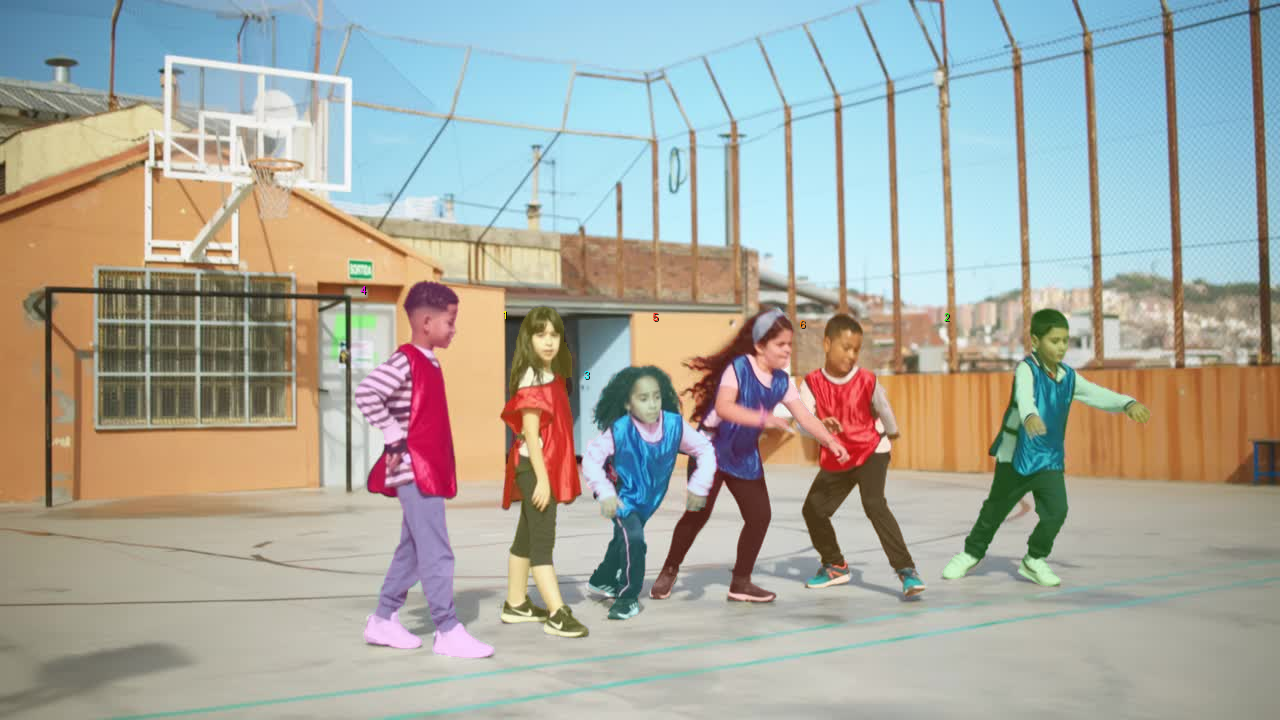

In [13]:
tool_request = {
    "tool_name": tool_call["name"],
    "args": tool_args,
    "tool_call_id": "call_1",
}
tool_resp = requests.post(f"{TOOL_SERVER_URL}/execute", json=tool_request, timeout=300)
require(tool_resp.ok, f"Tool server call failed: {tool_resp.status_code} {tool_resp.text[:500]}")
tool_payload = tool_resp.json()
require(tool_payload.get("ok") is True, f"Tool execution not ok: {json.dumps(tool_payload)[:600]}")

result = tool_payload.get("result", {})
viz_b64 = result.get("all_masks_viz_base64")
require(viz_b64 is not None, "Tool did not return all_masks_viz_base64")

boxes = result.get("boxes") or []
scores = result.get("scores") or []
tool_result_compact = {
    "model": result.get("model"),
    "prompt": result.get("prompt"),
    "num_masks": result.get("num_masks"),
    "boxes": [[round(float(v), 1) for v in box] for box in boxes],
    "scores": [round(float(s), 4) for s in scores],
}
tool_result_compact = {k: v for k, v in tool_result_compact.items() if v is not None}
tool_result_compact_json = json.dumps(tool_result_compact, ensure_ascii=False)
require("base64" not in tool_result_compact_json, "Compact tool summary should not include base64 payloads")

viz_path = OUTPUT_DIR / "sam3_viz_from_tool.png"
viz_bytes = base64.b64decode(viz_b64)
viz_path.write_bytes(viz_bytes)

print("tool result keys:", list(result.keys()))
print("compact tool result:", tool_result_compact_json)
print("saved:", viz_path, "bytes:", len(viz_bytes))
display(Image.open(viz_path))


In [14]:
tool_response_image_data_url = f"data:image/png;base64,{viz_b64}"

messages2 = messages + [
    {
        "role": "assistant",
        "tool_calls": [
            {
                "id": "call_1",
                "type": "function",
                "function": {"name": tool_call["name"], "arguments": tool_args},
            }
        ],
    },
    {
        "role": "tool",
        "tool_call_id": "call_1",
        "name": tool_call["name"],
        "content": [
            {
                "type": "text",
                "text": f"SAM3 structured result (no image payload): {tool_result_compact_json}",
            },
            {
                "type": "image",
                "image": tool_response_image_data_url,
            }
        ],
    },
]

prompt2 = processor.apply_chat_template(
    messages2,
    tools=TOOLS,
    tokenize=False,
    add_generation_prompt=True,
)

print(prompt2[:900])
print("...")
print(prompt2[-500:])
print_token_preview("prompt2", prompt2)


<|im_start|>system
You are a precise visual assistant. Follow user instructions carefully.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"function": {"name": "SAM3_Segment_Tool", "description": "Call an external SAM3 segmentation server with a prompt and image.", "parameters": {"type": "object", "properties": {"prompt": {"type": "string", "description": "Text prompt to segment"}, "image_path": {"type": "string", "description": "Local image path"}, "image_base64": {"type": "string", "description": "Base64 image data (use instead of image_path)"}, "return_masks_png_b64": {"type": "boolean", "description": "Whether to return PNG masks as base64"}, "return_all_masks_viz": {"type": "boolean", "description": "Whether to return all-mask visualization"}, "max_masks": {"type": "integ
...
ool_call><|im_end|>
<|im_start|>user
<tool_response>
SAM3 structured result (no image payload):

In [15]:
pass2 = call_completions(prompt2, image_data_urls=[original_image_data_url, tool_response_image_data_url], max_tokens=1000, stop=["<|im_end|>"])
final_text = pass2["choices"][0]["text"].strip()
require(final_text, "Model returned empty final_text after tool-response image")
print("Final answer:")
print(final_text)
print("pass2 usage:", pass2.get("usage"))
print_token_preview("final_text", final_text, head=80, tail=0)


Final answer:
The SAM3 segmentation tool returned 6 masks for the prompt "children". Each mask corresponds to a detected child in the image. Therefore, there are 6 children visible.
pass2 usage: {'prompt_tokens': 779, 'total_tokens': 815, 'completion_tokens': 36, 'prompt_tokens_details': None}

[final_text] total_tokens=35 shown=35 hidden_base64=0 hidden_vision=0
ids: 785 46587 18 59752 5392 5927 220 21 26135 369 279 9934 330 5864 3263 8886 6911 33210 311 264 16507 1682 304 279 2168 13 15277 11 1052 525 220 21 2841 9434 13
decoded: The SAM3 segmentation tool returned 6 masks for the prompt "children". Each mask corresponds to a detected child in the image. Therefore, there are 6 children visible.
